In [2]:
from typing import Any

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, random_split
import pandas as pd
import matplotlib.pyplot as plt
import torchvision
#import cv2

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [2]:
sample_images = np.load("A1 Data\\A1_data_75\\images.npy")
sample_labels = np.load("A1 Data\\A1_data_75\\labels.npy")

all_images = np.load("A1 Data\\A1_data_150\\images.npy")
all_labels = np.load("A1 Data\\A1_data_150\\labels.npy")

sample_images

array([[[130, 134, 141, ..., 147, 143, 146],
        [142, 136, 122, ..., 150, 151, 153],
        [140, 129, 143, ..., 141, 141, 145],
        ...,
        [135, 111,  74, ..., 106, 130, 135],
        [ 81, 100, 109, ..., 129, 104, 132],
        [ 92, 123, 120, ..., 103,  84,  80]],

       [[138, 155, 148, ..., 136, 136, 128],
        [138, 142, 138, ..., 126, 121, 134],
        [125, 143, 143, ..., 130, 139, 135],
        ...,
        [101,  79,  65, ...,  94,  98,  98],
        [ 75,  70,  84, ...,  95, 100,  90],
        [ 80, 104, 107, ...,  96, 103,  91]],

       [[137, 131, 148, ..., 153, 157, 157],
        [145, 142, 141, ..., 150, 153, 153],
        [139, 143, 146, ..., 149, 148, 145],
        ...,
        [ 97, 114, 121, ...,  91, 101, 104],
        [121, 121, 100, ..., 100,  85,  76],
        [134, 132, 112, ...,  95,  97,  95]],

       ...,

       [[128, 124, 133, ..., 146, 147, 148],
        [141, 144, 149, ..., 152, 152, 152],
        [132, 126, 125, ..., 147, 149, 148

In [3]:
sample = sample_images[0]
sample

array([[130, 134, 141, ..., 147, 143, 146],
       [142, 136, 122, ..., 150, 151, 153],
       [140, 129, 143, ..., 141, 141, 145],
       ...,
       [135, 111,  74, ..., 106, 130, 135],
       [ 81, 100, 109, ..., 129, 104, 132],
       [ 92, 123, 120, ..., 103,  84,  80]], shape=(75, 75), dtype=uint8)

In [4]:
sample_labels

array([[ 0,  0],
       [ 0,  0],
       [ 0,  0],
       ...,
       [11, 59],
       [11, 59],
       [11, 59]], shape=(18000, 2))

In [3]:
def transform_labels(sample):
    val = float(sample[0])
    if not 0 <= sample[1] <= 59:
        raise ValueError("minutes placement must be between 0 and 59")
    
    floating = sample[1] * (0.99 / 59)

    return val + floating

In [4]:
float_labels = np.array([transform_labels(x) for x in sample_labels])
float_labels[20:60]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.01677966, 0.01677966, 0.01677966, 0.01677966, 0.01677966,
       0.01677966, 0.01677966, 0.01677966, 0.01677966, 0.01677966,
       0.01677966, 0.01677966, 0.01677966, 0.01677966, 0.01677966,
       0.01677966, 0.01677966, 0.01677966, 0.01677966, 0.01677966,
       0.01677966, 0.01677966, 0.01677966, 0.01677966, 0.01677966,
       0.03355932, 0.03355932, 0.03355932, 0.03355932, 0.03355932,
       0.03355932, 0.03355932, 0.03355932, 0.03355932, 0.03355932])

In [5]:
# Transform data, so it can be processed by the PyTorch NN
X = torch.from_numpy(sample_images)
y = torch.from_numpy(float_labels)

dataset = TensorDataset(X, y)

In [6]:
class NNRegressor(nn.Module):
    def __init__(self, in_channels, num_classes):
        super(NNRegressor, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, 256, kernel_size=5)
        self.conv2 = nn.Conv2d(256, 64, kernel_size=5)
        self.conv3 = nn.Conv2d(64, 16, kernel_size=5)
        self.conv2_drop = nn.Dropout2d(p=0.1)
        self.max_pool1 = nn.MaxPool2d(kernel_size=2)
        self.max_pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.max_pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.nn = nn.Sequential(
            nn.Linear(16*5*5, 128),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            nn.Linear(16, out_features=num_classes),
            #nn.Softmax()
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.max_pool1(x)
        x = self.conv2(x)
        x = self.max_pool2(x)
        x = self.conv2_drop(x)
        x = self.conv3(x)
        x = self.max_pool3(x)
        
        x = torch.flatten(x, start_dim=1)
        
        x = self.nn(x)
        return x

Training Loop

In [7]:
learning_rate = 0.001
batch_size = 64
epochs = 5

generator = torch.Generator().manual_seed(42) # for reproducibility purposes

train_set, val_set, test_set = random_split(
    dataset, [0.8, 0.1, 0.1], generator=generator
)

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)


model = NNRegressor(in_channels=1, num_classes=1).to(device)
loss_function = nn.SmoothL1Loss(beta=4.0)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.015)

In [ ]:
# training process

"""""""""""""""""""""""""""
for n in range(epochs):
    print(f"Epoch [{n + 1}/{epochs}]")
    cumulated_loss = 0
    for i, (X, y) in enumerate(train_loader):
        X, y = X.float().to(device).unsqueeze(1), y.float().to(device).unsqueeze(1)

        optimizer.zero_grad()

        pred = model(X)

        loss = loss_function(pred, y)
        cumulated_loss += loss.item()
        print(f"Batch {i+1} Loss: {loss.item()}")
        
        loss.backward()

        optimizer.step()

    print(f"End of epoch. Cumulated loss: {cumulated_loss}")
"""""""""""""""""""""""""""""""""

for n in range(epochs):
    cumulated_loss = torch.zeros((), device=device)

    for X, y in train_loader:
        X = X.float().to(device).unsqueeze(1)
        y = y.float().to(device).unsqueeze(1)

        optimizer.zero_grad()
        pred = model(X)
        loss = loss_function(pred, y)
        loss.backward()
        optimizer.step()

        cumulated_loss += loss.detach()

    print(f"End of epoch. Cumulated loss: {cumulated_loss.item():.4f}")

End of epoch. Cumulated loss: 595.4365
End of epoch. Cumulated loss: 414.3835


KeyboardInterrupt: 

It took too long...let's try a different, smaller architecure instead!

In [8]:
class SmallerNNRegressor(nn.Module):
    def __init__(self, in_channels, num_classes):
        super(SmallerNNRegressor, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=5, dilation=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=5, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 32, kernel_size=5, dilation=2),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten()

        )
        self.fn = nn.Sequential(
            nn.Linear(32*4*4, 64),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(p=0.2),

            nn.Linear(16, out_features=num_classes),
            #nn.Softmax()
        )

    def forward(self, x):
        x = self.features(x)
        x = self.fn(x)
        return x

End of epoch. Cumulated loss: 427.3821
End of epoch. Cumulated loss: 383.1720
End of epoch. Cumulated loss: 359.3539
End of epoch. Cumulated loss: 352.4575
End of epoch. Cumulated loss: 334.2692


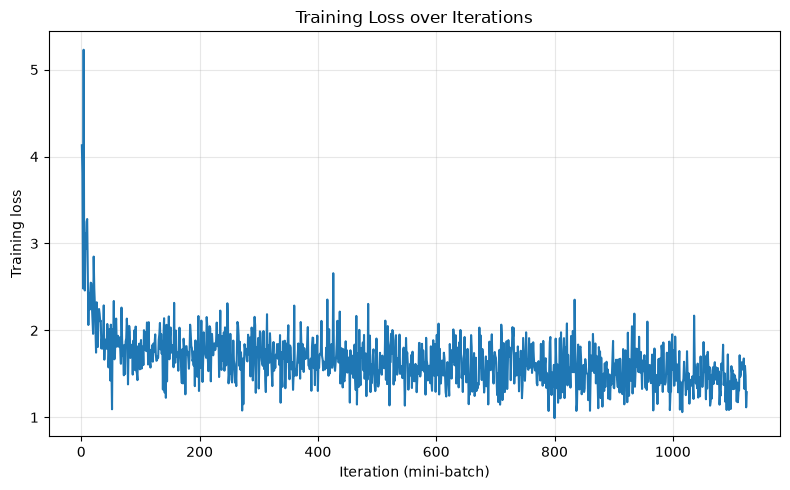

In [9]:
model = SmallerNNRegressor(in_channels=1, num_classes=1).to(device)
loss_function = nn.SmoothL1Loss(beta=4.0)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.015)
loss_history = []

for n in range(epochs):
    cumulated_loss = torch.zeros((), device=device)

    for X, y in train_loader:
        X = X.float().to(device).unsqueeze(1)
        y = y.float().to(device).unsqueeze(1)

        optimizer.zero_grad()
        pred = model(X)
        loss = loss_function(pred, y)
        loss_history.append(loss.item())
        loss.backward()
        optimizer.step()

        cumulated_loss += loss.detach()

    print(f"End of epoch. Cumulated loss: {cumulated_loss.item():.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel("Iteration (mini-batch)")
plt.ylabel("Training loss")
plt.title("Training Loss over Iterations")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Evaluation Stage

In [15]:
model.eval()  # disables dropout
val_loss_sum = 0.0
num_examples = 0

def common_sense_error_minutes(pred, target):
    def to_clock_minutes(x):
        x = torch.remainder(x.squeeze(-1), 12)
        hour = torch.floor(x)
        minute = (x - hour) * (59 / 0.99)  # invert your label encoding
        return torch.remainder(hour * 60 + minute, 720)

    pred_minutes = to_clock_minutes(pred)
    target_minutes = to_clock_minutes(target)

    difference = torch.abs(pred_minutes - target_minutes)
    return torch.minimum(difference, 720 - difference)

with torch.inference_mode():  # no gradients needed for validation
    for X, y in val_loader:
        X = X.float().to(device).unsqueeze(1)
        y = y.float().to(device).unsqueeze(1)

        pred = model(X)
        batch_loss = common_sense_error_minutes(pred, y)

        # Weight each batch by its size, including a possibly smaller last batch
        val_loss_sum += batch_loss.mean().item() * X.size(0)
        num_examples += X.size(0)

avg_val_loss = val_loss_sum / num_examples
print(f"Validation loss: {avg_val_loss:.4f}")

Validation loss: 156.4534


Very good already! But can we try to smooth more the loss landscape?

In [15]:
class BatchNormalizedNN(nn.Module):
    def __init__(self, in_channels, num_classes):
            super(BatchNormalizedNN, self).__init__()
            self.features = nn.Sequential(
                nn.Conv2d(in_channels, 32, kernel_size=5, dilation=2),
                nn.BatchNorm2d(num_features=32),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2),
    
                nn.Conv2d(32, 64, kernel_size=5, padding=1),
                nn.BatchNorm2d(num_features=64),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2),
    
                nn.Conv2d(64, 32, kernel_size=5, dilation=2),
                nn.BatchNorm2d(num_features=32),
                nn.ReLU(),
                nn.MaxPool2d(kernel_size=2, stride=2),
    
                nn.AdaptiveAvgPool2d((4, 4)),
                nn.Flatten()
    
            )
            self.fn = nn.Sequential(
                nn.Linear(32*4*4, 64),
                nn.ReLU(),
                nn.Dropout(p=0.2),
    
                nn.Linear(64, 32),
                nn.ReLU(),
                nn.Dropout(p=0.2),
    
                nn.Linear(32, 16),
                nn.ReLU(),
                nn.Dropout(p=0.2),
    
                nn.Linear(16, out_features=num_classes),
                #nn.Softmax()
            )
    
    def forward(self, x):
        x = self.features(x)
        x = self.fn(x)
        return x

End of epoch. Cumulated loss: 350.0220
End of epoch. Cumulated loss: 270.2681
End of epoch. Cumulated loss: 246.8996
End of epoch. Cumulated loss: 228.1446
End of epoch. Cumulated loss: 204.6856


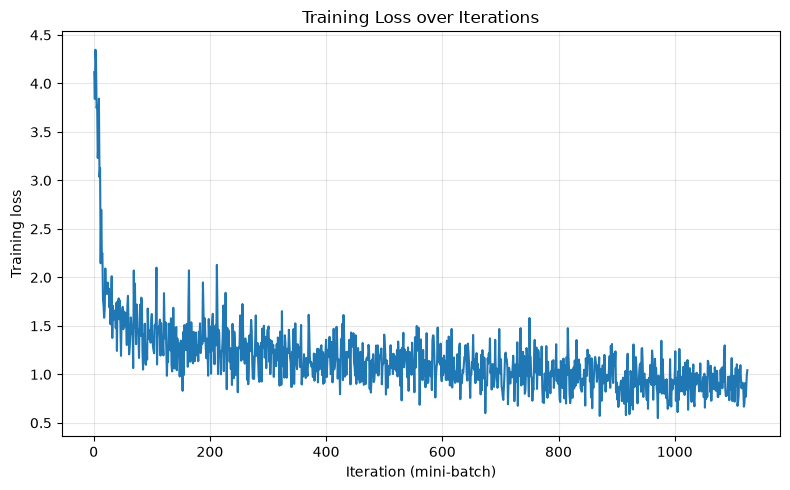

In [16]:
model = BatchNormalizedNN(in_channels=1, num_classes=1).to(device)
loss_function = nn.SmoothL1Loss(beta=4.0)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.015)
loss_history = []

for n in range(epochs):
    cumulated_loss = torch.zeros((), device=device)

    for X, y in train_loader:
        X = X.float().to(device).unsqueeze(1)
        y = y.float().to(device).unsqueeze(1)

        optimizer.zero_grad()
        pred = model(X)
        loss = loss_function(pred, y)
        loss_history.append(loss.item())
        loss.backward()
        optimizer.step()

        cumulated_loss += loss.detach()

    print(f"End of epoch. Cumulated loss: {cumulated_loss.item():.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel("Iteration (mini-batch)")
plt.ylabel("Training loss")
plt.title("Training Loss over Iterations")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### Evaluation Stage

In [ ]:
model.eval()  # once more, to disable dropout
val_loss_sum = 0.0
num_examples = 0

with torch.inference_mode():
    for X, y in val_loader:
        X = X.float().to(device).unsqueeze(1)
        y = y.float().to(device).unsqueeze(1)

        pred = model(X)
        batch_loss = common_sense_error_minutes(pred, y)

        val_loss_sum += batch_loss.mean().item() * X.size(0)
        num_examples += X.size(0)

avg_val_loss = val_loss_sum / num_examples
print(f"Validation loss: {avg_val_loss:.4f}")

Validation loss: 140.5157


A slightly better loss.

### Trigonometric Encoding

In [25]:
def trigonometric_encoding(sample):
    hour_angle = (2*np.pi * (sample[0] + sample[1] / 60)) / 12
    min_angle = (2* np.pi * sample[1]) / 60

    return [hour_angle, min_angle]

In [46]:
test = trigonometric_encoding(sample_labels[2])
print("Time: ", sample_labels[312])
print("Angle: ", test)

Time:  [ 0 12]
Angle:  [np.float64(0.0), np.float64(0.0)]


In [47]:
class NNTrigonometricEnconder(nn.Module):
    def __init__(self, in_channels, num_classes=4, **kwargs: Any):
        super(NNTrigonometricEnconder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels=in_channels, out_channels=64, kernel_size=6),
            nn.Sigmoid(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(64, 32, kernel_size=6),
            nn.Sigmoid(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 16, kernel_size=3),
            nn.Sigmoid(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3),
            nn.Sigmoid(),
            nn.MaxPool2d(kernel_size=2),

            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten()
        )

        self.nn = nn.Sequential(
            nn.Linear(32*4*4, 132),
            nn.ReLU(),

            nn.Linear(132, 64),
            nn.ReLU(),
            nn.Dropout(p=0.4),

            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(p=0.4),

            nn.Linear(64, num_classes),
            nn.Tanh() # here, in the output layer, it is pertinent to advocate for the use of a tangent function
                      # for we want to output the sine and cosine values of our angles, 
                      # thus limiting our possible values to (-1, 1)
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.nn(x)
        return x

In [1]:
# Transform data, so it can be processed by the PyTorch NN
angle_labels = np.array([trigonometric_encoding(sample) for sample in sample_labels])

sin_cos_labels = np.array([[np.cos(x[0]), np.sin(x[0]), np.cos(x[1]), np.sin(1)] for x in angle_labels])
X = torch.from_numpy(sample_images)
y = torch.from_numpy(sin_cos_labels)

print("X: ", X.size())
print("y: ", y.size())

dataset = TensorDataset(X, y)

# Some Hyperparameters
learning_rate = 1e-4
batch_size = 64
epochs = 5

generator = torch.Generator().manual_seed(42) # for reproducibility purposes

train_set, val_set, test_set = random_split(
    dataset, [0.8, 0.1, 0.1], generator=generator
)

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)


NameError: name 'np' is not defined

End of epoch. Cumulated loss: 45.0998
End of epoch. Cumulated loss: 45.0873
End of epoch. Cumulated loss: 45.0513
End of epoch. Cumulated loss: 45.0252
End of epoch. Cumulated loss: 45.0140


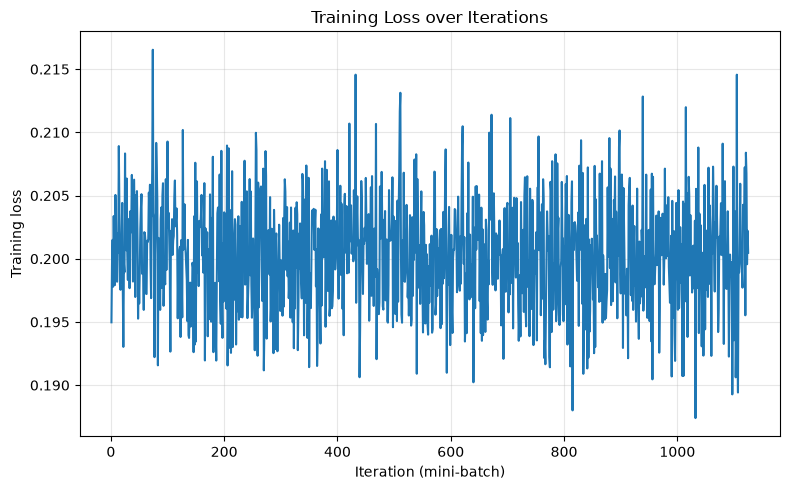

In [51]:
model = NNTrigonometricEnconder(in_channels=1, num_classes=4).to(device)
loss_function = nn.SmoothL1Loss(beta=1.5)

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=0.015)
loss_history = []

for n in range(epochs):
    cumulated_loss = torch.zeros((), device=device)

    for X, y in train_loader:
        X = X.float().to(device).unsqueeze(1)
        y = y.float().to(device)

        optimizer.zero_grad()
        pred = model(X)
        loss = loss_function(pred, y)
        loss_history.append(loss.item())
        loss.backward()
        optimizer.step()

        cumulated_loss += loss.detach()

    print(f"End of epoch. Cumulated loss: {cumulated_loss.item():.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel("Iteration (mini-batch)")
plt.ylabel("Training loss")
plt.title("Training Loss over Iterations")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Evaluation Stage

In [52]:
model.eval()  # once more, to disable dropout
val_loss_sum = 0.0
num_examples = 0

with torch.inference_mode():
    for X, y in val_loader:
        X = X.float().to(device).unsqueeze(1)
        y = y.float().to(device).unsqueeze(1)

        pred = model(X)
        batch_loss = common_sense_error_minutes(pred, y)

        val_loss_sum += batch_loss.mean().item() * X.size(0)
        num_examples += X.size(0)

avg_val_loss = val_loss_sum / num_examples
print(f"Validation loss: {avg_val_loss:.4f}")

Validation loss: 42.8032
